# USD/ARS · tuning and walk-forward validation
ARS per US dollar (Yahoo `ARS=X`). XGBoost predicts the log return $\ln(S_2/S_1)$ from elapsed days $(t_2-t_1)/86400$ when times are measured in seconds. The price forecast is $S_1\exp(\hat y)$. The blend is $S_1+w_h(\hat S_{XGB}-S_1)$, where each horizon has its own weight. All timestamps, including weekends, are eligible.

Run from the repository root with the worker's SQLite database beside this notebook or set USD_ARS_DB. The outputs include a deployment configuration, a public dashboard snapshot, and optionally an MLflow run. The source database is opened read-only.

In [1]:
import os
import json
import sqlite3
from pathlib import Path
from contextlib import closing
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fx_model import CONFIG, DAY, HORIZONS, TZ, WINDOW, fit_model, forecast, historical_window, make_pairs, match

DB = Path(os.environ.get("USD_ARS_DB", "usd_ars.sqlite")).resolve()
with closing(sqlite3.connect(DB.as_uri() + "?mode=ro", uri=True)) as db:
    observations = pd.read_sql_query("SELECT bar_end, close FROM prices ORDER BY bar_end", db)
prices = observations.set_index(pd.to_datetime(observations.bar_end, unit="s", utc=True)).close
assert prices.index.is_unique and prices.gt(0).all()
pairs = make_pairs(prices)
print(f"{len(prices):,} prices from {prices.index.min()} to {prices.index.max()}")

6,526 prices from 2022-11-23 03:00:00+00:00 to 2026-11-20 23:00:00+00:00


## Selection and evaluation
Use scheduled origins at 17:00 Buenos Aires time every five calendar days. Each forecast takes the latest close available by that origin. The actual is the first observed close at or after the target within 48 hours. The historical archive assumes prices were available at bar end; historical vendor arrival timestamps were unavailable. Each sampled origin uses the same model-fitting routine as the worker's first daily fit and up to four trailing years. Earlier origins have shorter windows.

For each horizon, reserve roughly the final 120 days of **target dates** for evaluation. Select XGBoost settings on earlier forecasts whose outcomes matured before the first evaluation origin. Fit the blend on those same selection forecasts, then freeze both choices for the entire evaluation. The model itself is refitted using matured pairs at each sampled origin. Test forecasts remain in the export once their target date arrives, even if a matching quote has yet to arrive. The full 48-hour window is reserved before evaluation when selecting settings. Long-horizon scored returns overlap and the earlier notebook already examined this market period; prospective monitoring provides the next independent check.

In [2]:
params_grid = [{"max_depth": d, "n_estimators": n, "learning_rate": rate}
               for d, n, rate in product([1, 3, 5], [50, 100], [0.03, 0.10])]
params_grid.append({"max_depth": 3, "n_estimators": 100, "learning_rate": 0.05})
weights = np.linspace(0, 1, 101)
last = prices.index[-1]
first_day = prices.index[0].tz_convert(TZ).normalize() + pd.DateOffset(years=1, days=45)
origins = pd.date_range(first_day + pd.Timedelta(hours=17), last.tz_convert(TZ), freq="5D")

/tmp/ipykernel_75034/2861862406.py:7: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  origins = pd.date_range(first_day + pd.Timedelta(hours=17), last.tz_convert(TZ), freq="5D")


In [3]:
def design(h):
    offset = HORIZONS[h]
    test_start = (last - 120*DAY).tz_convert(TZ) - offset
    rows = []
    for origin in origins:
        due = origin + offset
        if due > last:
            continue
        split = "test" if origin >= test_start else "selection"
        if split == "selection" and due + WINDOW >= test_start:
            continue
        base_i = prices.index.searchsorted(origin, side="right") - 1
        end, actual = match(prices, due)
        rows.append(dict(origin=origin, due=due, end=end, actual=actual, split=split,
                         base=float(prices.iloc[base_i]), base_at=prices.index[base_i]))
    return pd.DataFrame(rows)

designs = {h: design(h) for h in HORIZONS}
# Pool all horizon classes for fitting as in the initial notebook. A model trained only
# on nearly identical elapsed times within one horizon would have little to split on.
predictions = []
for origin in origins:
    training = historical_window(pairs, origin)
    counts = training.h.value_counts()
    active = {h: group.loc[group.origin.eq(origin)].iloc[0]
              for h, group in designs.items() if group.origin.eq(origin).any() and counts.get(h,0)>=30}
    if not active:
        continue
    x = pd.DataFrame({"elapsed": [(r.due-r.base_at)/DAY for r in active.values()]})
    for candidate, params in enumerate(params_grid):
        model = fit_model(training, params)
        returns = model.predict(x).astype(float)
        for (h,r), ret in zip(active.items(),returns):
            predictions.append(dict(horizon=h, candidate=candidate, origin=r.origin,
                due=r.due,end=r.end,base=r.base,actual=r.actual,split=r.split,
                predicted=r.base*np.exp(ret)))
replay = pd.DataFrame(predictions)

## Horizon settings and price weights
Rank base candidates by price MAE on matched selection rows. For the winning candidate minimize selection MAE across XGBoost weights from 0 to 1 in 0.01 steps. Ties use the first candidate and the smaller weight. Both boundaries are valid. The test forecasts computed for the candidate grid above play no part in either selection.

In [4]:
specs, results, metrics, trials = {}, [], [], []
for h in HORIZONS:
    g = replay[replay.horizon.eq(h)]
    selection = g[g.split.eq("selection")].dropna(subset=["actual"]).copy()
    selection["ae"] = (selection.actual-selection.predicted).abs()
    scores = selection.groupby("candidate").ae.mean()
    if scores.empty:
        raise ValueError(f"{h}: insufficient matured selection forecasts")
    winner = int(scores.idxmin())
    val = selection[selection.candidate.eq(winner)]
    delta = (val.predicted-val.base).to_numpy()[:, None]
    errors = np.abs((val.actual-val.base).to_numpy()[:, None] - delta*weights)
    w = float(weights[errors.mean(axis=0).argmin()])
    specs[h] = {"params": params_grid[winner], "xgb_weight": round(w,2)}
    trials.extend(dict(horizon=h, candidate=int(k), selection_MAE=float(v),
                       **params_grid[int(k)]) for k,v in scores.items())
    test = g[g.split.eq("test") & g.candidate.eq(winner)].copy()
    assert val.end.max() < test.origin.min()
    test["blend"] = test.base+w*(test.predicted-test.base)
    test["midpoint"] = (test.base+test.predicted)/2
    scored = test.dropna(subset=["actual"])
    if scored.empty:
        raise ValueError(f"{h}: no matched test forecasts")
    results.append(test)
    metrics.append(dict(horizon=h, selection_n=len(val), test_issued=len(test), test_scored=len(scored),
        xgb_weight=w, **{name+"_MAE":(scored.actual-scored[field]).abs().mean()
        for name,field in [("baseline","base"),("XGB","predicted"),("half","midpoint"),("tuned","blend")]}))
summary = pd.DataFrame(metrics).set_index("horizon")
holdout = pd.concat(results, ignore_index=True)
display(pd.DataFrame({h: dict(**s["params"], xgb_weight=s["xgb_weight"],
                              no_change_weight=round(1-s["xgb_weight"],2)) for h,s in specs.items()}).T)
display(summary.round(2))

,max_depth,n_estimators,learning_rate,xgb_weight,no_change_weight
1D,5.0,100.0,0.10,0.10,0.90
7D,5.0,100.0,0.10,0.25,0.75
14D,5.0,100.0,0.10,0.24,0.76
1M,5.0,100.0,0.10,0.21,0.79
3M,1.0,50.0,0.03,0.21,0.79
6M,1.0,50.0,0.03,0.22,0.78
1Y,1.0,50.0,0.03,0.16,0.84


,selection_n,test_issued,test_scored,xgb_weight,baseline_MAE,XGB_MAE,half_MAE,tuned_MAE
horizon,,,,,,,,
1D,173,24,22,0.10,1.58,2.34,1.93,1.63
7D,172,24,24,0.25,7.99,7.24,7.16,7.57
14D,166,24,24,0.24,8.98,10.73,7.87,7.67
1M,161,24,24,0.21,15.99,22.49,9.65,10.54
3M,142,24,24,0.21,67.20,53.35,23.92,41.88
6M,108,23,22,0.22,123.09,181.00,30.99,57.17
1Y,37,24,24,0.16,133.66,992.86,429.60,54.49


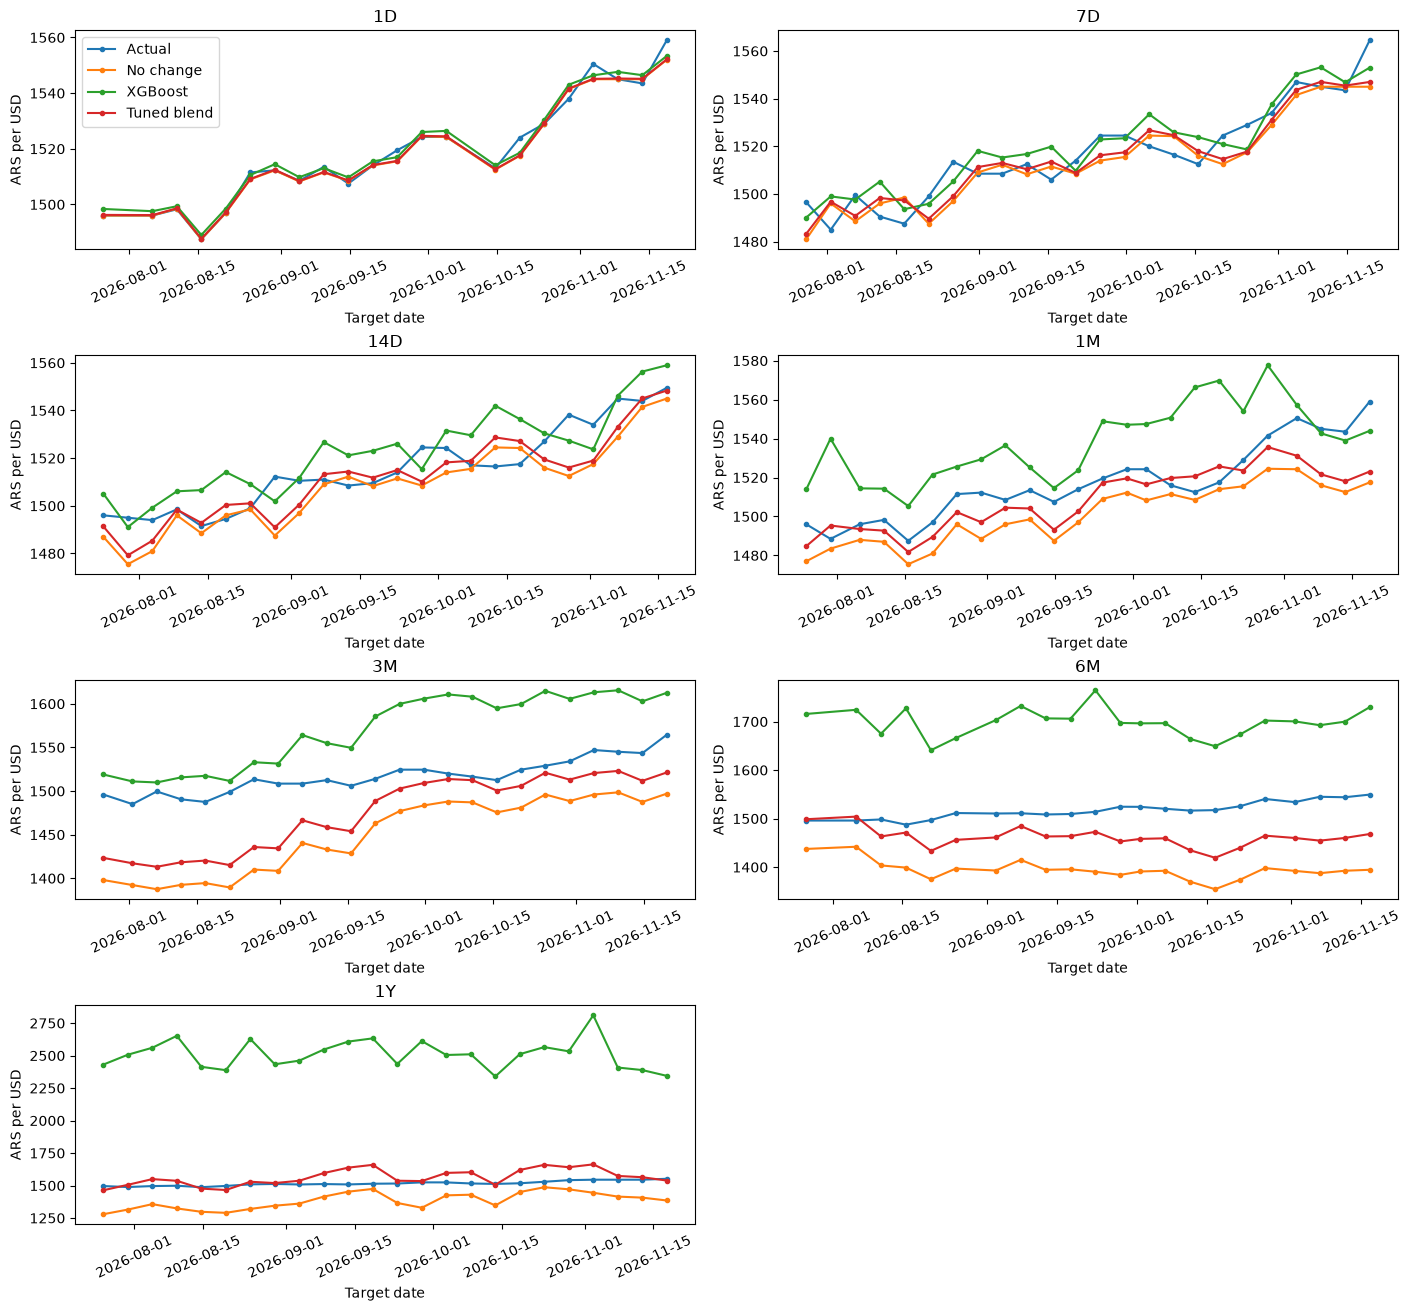

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(14,13), constrained_layout=True)
for ax, (h, group) in zip(axes.flat, holdout.groupby("horizon",sort=False)):
    g = group.dropna(subset=["actual"]).sort_values("due")
    for col, label in [("actual","Actual"),("base","No change"),("predicted","XGBoost"),("blend","Tuned blend")]:
        ax.plot(g.due,g[col],marker=".",label=label)
    ax.set(title=h, ylabel="ARS per USD", xlabel="Target date")
    ax.tick_params(axis="x",labelrotation=25)
axes.flat[0].legend()
axes.flat[-1].set_visible(False)
plt.show()

## Publish the frozen settings and dashboard snapshot
The worker reads this JSON before each daily fit. Its version includes a hash of the configuration. The snapshot gives the dashboard a public, dated preview while the minute worker is offline. Its forecasts are reconstructed as of the last quote. Actual live issues remain in SQLite. Committing the snapshot after a new run refreshes the public preview.

In [6]:
config = {"schema":1,"match_window_hours":48,"data_end":last.isoformat(),"horizons":specs}
tmp = CONFIG.with_suffix(".tmp")
tmp.write_text(json.dumps(config,indent=2)+"\n")
tmp.replace(CONFIG)
out = Path("snapshot")
out.mkdir(exist_ok=True)
summary.to_csv(out/"metrics.csv")
holdout.to_csv(out/"holdout.csv",index=False)
pd.DataFrame(trials).to_csv(out/"selection.csv",index=False)
history = prices.loc[last-pd.DateOffset(years=1):]
history.groupby(history.index.tz_convert(TZ).normalize()).tail(1).rename("close").to_csv(out/"history.csv",index_label="time")
latest = []
for h,s in specs.items():
    m = fit_model(historical_window(pairs,last),s["params"])
    target = last.tz_convert(TZ)+HORIZONS[h]
    pred, blend = forecast(m,float(prices.iloc[-1]),last,target,s["xgb_weight"])
    latest.append(dict(horizon=h,issued_at=last,base_quote_at=last,target_at=target,
                       base_price=prices.iloc[-1],predicted_price=pred,blend_price=blend,
                       xgb_weight=s["xgb_weight"]))
pd.DataFrame(latest).to_csv(out/"forecast.csv",index=False)
display(pd.DataFrame(latest).round(2))

,horizon,issued_at,base_quote_at,target_at,base_price,predicted_price,blend_price,xgb_weight
0,1D,2026-11-20 23:00:00+00:00,2026-11-20 23:00:00+00:00,2026-11-21 20:00:00-03:00,1579.5,1581.03,1579.65,0.10
1,7D,2026-11-20 23:00:00+00:00,2026-11-20 23:00:00+00:00,2026-11-27 20:00:00-03:00,1579.5,1588.49,1581.75,0.25
2,14D,2026-11-20 23:00:00+00:00,2026-11-20 23:00:00+00:00,2026-12-04 20:00:00-03:00,1579.5,1596.87,1583.67,0.24
3,1M,2026-11-20 23:00:00+00:00,2026-11-20 23:00:00+00:00,2026-12-20 20:00:00-03:00,1579.5,1630.16,1590.14,0.21
4,3M,2026-11-20 23:00:00+00:00,2026-11-20 23:00:00+00:00,2027-02-20 20:00:00-03:00,1579.5,1693.63,1603.47,0.21
5,6M,2026-11-20 23:00:00+00:00,2026-11-20 23:00:00+00:00,2027-05-20 20:00:00-03:00,1579.5,1704.66,1607.04,0.22
6,1Y,2026-11-20 23:00:00+00:00,2026-11-20 23:00:00+00:00,2027-11-20 20:00:00-03:00,1579.5,1886.73,1628.66,0.16


## Record this experiment in MLflow
Set LOG_MLFLOW to True after installing MLflow. One run per horizon records its selected parameters, blend weight, sample counts, held-out MAEs, and the configuration. Use the Tracking UI to compare multiple executions on the same date range. See README for launch commands.

In [7]:
LOG_MLFLOW = os.getenv("LOG_MLFLOW","0") == "1"
if LOG_MLFLOW:
    import mlflow
    mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI","http://127.0.0.1:5000"))
    mlflow.set_experiment("USD-ARS horizon tuning")
    for h,s in specs.items():
        with mlflow.start_run(run_name=h+" "+last.date().isoformat()):
            mlflow.log_params(dict(horizon=h,data_end=last.isoformat(),xgb_weight=s["xgb_weight"],
                                   match_window_hours=config["match_window_hours"], train_years=4, grid_size=len(params_grid), **s["params"]))
            mlflow.log_metrics(summary.loc[h].drop("xgb_weight").to_dict())
            mlflow.log_artifact(str(CONFIG))
            mlflow.log_table(holdout.loc[holdout.horizon.eq(h)].drop(columns=["candidate"]).astype(
                {"origin":str,"due":str,"end":str}),"test_predictions.json")

2026/11/22 15:15:34 INFO mlflow.tracking.fluent: Experiment with name 'USD-ARS horizon tuning' does not exist. Creating a new experiment.


🏃 View run 1D 2026-11-20 at: http://127.0.0.1:5000/#/experiments/1/runs/e5913b81e66b4a449da11c3dda9e1c8c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run 7D 2026-11-20 at: http://127.0.0.1:5000/#/experiments/1/runs/a86e4169a1d249e3a2465bb0e4420802
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run 14D 2026-11-20 at: http://127.0.0.1:5000/#/experiments/1/runs/dfa4cadea3c24fca97236e3eb60242ee
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run 1M 2026-11-20 at: http://127.0.0.1:5000/#/experiments/1/runs/dbe1e4f317ab4abfab5614e754a5a489
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run 3M 2026-11-20 at: http://127.0.0.1:5000/#/experiments/1/runs/184c732ae7fc4142b1ea965cdb9fba2e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run 6M 2026-11-20 at: http://127.0.0.1:5000/#/experiments/1/runs/9095ca7e408b40e780337fbdb888fc83
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View ru